In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from rollout_loader import load_rollouts
from sklearn.preprocessing import StandardScaler

In [2]:
torch.manual_seed(42)

In [29]:
# rollout loader
rls = load_rollouts( directory='./origin_data')  # looks for ./data_1.pkl or ./1.pkl, up to 4
print(f"Loaded {len(rls)} rollouts")
print("First rollout keys lengths:",len(rls[0].angle_diff_all),len(rls[0].tau_cmd_all))

Loaded 200 rollouts
First rollout keys lengths: 2500 2500


In [9]:
rls[0].angle_diff_all

[array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175,  0.      , -0.00261 ,
         0.      ]),
 array([ 0.      ,  0.002175,  0.      ,  0.002175

In [25]:
rls[0].velocity_diff_all

[array([ 0.   ,  2.175,  0.   ,  2.175,  0.   , -2.61 ,  0.   ]),
 array([-2.41807782e-17,  1.75761750e+00,  4.18619937e-17,  1.75761750e+00,
        -2.65014947e-17, -2.10914100e+00, -4.52814895e-17]),
 array([-9.56484895e-17,  1.41953767e+00,  2.40578125e-17,  1.41953767e+00,
         9.70266055e-17, -1.70344521e+00, -6.17655335e-17]),
 array([-7.60139810e-17,  1.14569302e+00,  2.39476563e-17,  1.14569302e+00,
         7.83244769e-17, -1.37483162e+00, -6.66065693e-17]),
 array([-6.22091403e-17,  9.23878844e-01,  1.41871134e-17,  9.23878844e-01,
         9.22251348e-17, -1.10865461e+00, -6.70365844e-17]),
 array([-7.21932266e-17,  7.44209363e-01,  1.55716248e-17,  7.44209363e-01,
         1.13282093e-16, -8.93051236e-01, -7.07178828e-17]),
 array([-7.04781003e-17,  5.98677084e-01,  1.97201196e-17,  5.98677084e-01,
         8.57462429e-17, -7.18412501e-01, -7.61437050e-17]),
 array([-7.08749029e-17,  4.80795938e-01,  1.21649769e-17,  4.80795938e-01,
         9.81420964e-17, -5.76955126

In [26]:
rls[0].tau_cmd_all

[array([ 9.95730155e-14,  6.24666129e+02,  1.33635730e-13, -2.85593989e+02,
         2.62972731e-14, -2.39428136e+02,  7.83193949e-15]),
 array([ 7.22352058e-14,  4.99989220e+02,  1.12097568e-13, -2.31136240e+02,
         1.86526317e-14, -1.93919501e+02,  5.73924028e-15]),
 array([ 4.65559520e-14,  3.98766363e+02,  9.32984865e-14, -1.86795463e+02,
         1.94849836e-14, -1.57054401e+02,  3.63219006e-15]),
 array([ 3.83667357e-14,  3.16633691e+02,  7.61362589e-14, -1.50743338e+02,
         1.61729699e-14, -1.27191451e+02,  2.09059126e-15]),
 array([ 3.38096530e-14,  2.50021797e+02,  6.25502545e-14, -1.21463675e+02,
         1.59329700e-14, -1.03000835e+02,  6.63414755e-16]),
 array([ 2.47282872e-14,  1.96017315e+02,  5.30671192e-14, -9.77058338e+01,
         1.51886015e-14, -8.34052077e+01, -3.42467956e-17]),
 array([ 1.56190914e-14,  1.52246354e+02,  4.28142941e-14, -7.84424925e+01,
         1.06467533e-14, -6.75317877e+01, -7.49100205e-16]),
 array([ 1.09318333e-14,  1.16777198e+02,

In [4]:
effort_limits_from_urdf = np.array([87,87,87,87,12,12,12])
joint_vel_limits = np.array([2.175, 2.175, 2.175, 2.175, 2.61, 2.61, 2.61])
lower_limits = np.array([-2.8973, -1.7628, -2.8973, 0.0, -2.8973, -0.0175, -2.8973])
upper_limits = np.array([2.8973, 1.7628, 2.8973, 3.002, 2.8973, 3.7525, 2.8973])

In [48]:
# 1. Data Preparation
X = []
Y = []

for rollout in rls:
    for angle_diff,velocity_diff, tau in zip(rollout.angle_diff_all, rollout.velocity_diff_all, rollout.tau_cmd_all):
        #x = np.concatenate([angle_diff, velocity_diff])
        X.append(angle_diff)
        Y.append(tau) 


X = np.array(X)  # shape: [num_samples, num_joints]
Y = np.array(Y)  # shape: [num_samples, num_joints]

In [222]:
outliers = set()
for i in range(len(Y)):
    for j in range(7):
        if(Y[i][j]>effort_limits_from_urdf[j] or Y[i][j]<-effort_limits_from_urdf[j]):
            #print(i,Y[i])
            outliers.add(i)
            continue

In [224]:
len(outliers)

3055

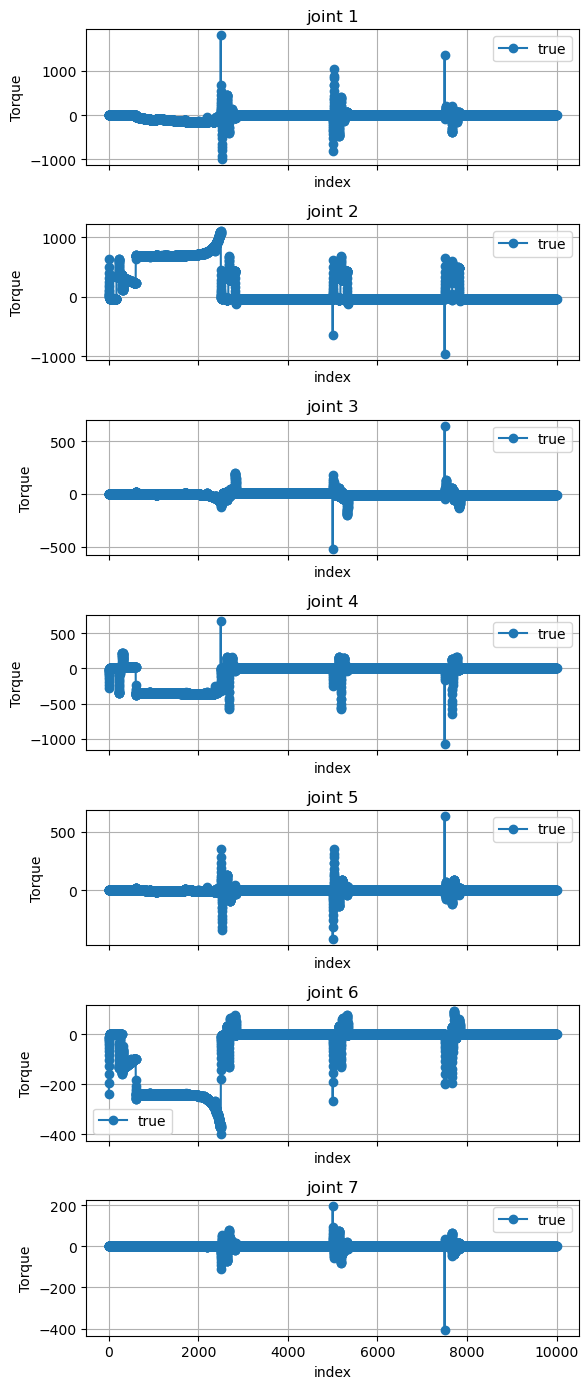

In [215]:
#show torqur values
fig, axes = plt.subplots(nrows=7, ncols=1, figsize=(6, 14), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(Y[:,i] , label='true', marker='o')
    #ax.plot(all_preds[:,i] , label='predict', marker='x')
  
    ax.set_title(f'joint {i+1}')
    ax.set_xlabel('index')
    ax.set_ylabel('Torque')
    ax.legend()
    ax.grid()
    #ax.set_ylim(-200,200)

plt.tight_layout()
#plt.savefig("torque_comparison_all.png", dpi=300)
plt.show()
    
    

In [49]:

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [50]:
# Download and load the training and test datasets


# Step 1: 
X_trainval, X_test, Y_trainval, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# Step 2: 
X_train, X_val, Y_train, Y_val = train_test_split(X_trainval, Y_trainval, test_size=0.2, random_state=42)


In [51]:
# Create data loaders
# train_loader 
X_train_tensor = torch.tensor(X_train, dtype=torch.float)
Y_train_tensor = torch.tensor(Y_train, dtype=torch.float)

X_val_tensor = torch.tensor(X_val, dtype=torch.float)
Y_val_tensor = torch.tensor(Y_val, dtype=torch.float)

X_test_tensor = torch.tensor(X_test, dtype=torch.float)
Y_test_tensor = torch.tensor(Y_test, dtype=torch.float)

train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, Y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, Y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [52]:
#the number of parameters in the shallow network is 32*784+32+10*32+10=25,450
#the number of parameters in the deep network is 30*784+30+28*30+28+26*28+26+10*26+10=25442
#deep network
class DMLP(nn.Module):
    def __init__(self):
        super(DMLP, self).__init__()
        #self.flatten = nn.Flatten()
        #self.register_buffer("effort", torch.tensor(effort_limits_from_urdf).float().unsqueeze(0))  # shape [1, n_joints]
        self.l1 = nn.Linear(7, 128)
        #self.norm1 = nn.LayerNorm(128)
        self.l2 = nn.Linear(128, 128)
        #self.norm2 = nn.LayerNorm(128)
        self.l3 = nn.Linear(128, 64)
       # self.norm3 = nn.LayerNorm(64)
        self.output = nn.Linear(64, 7)     # Hidden layer to output layer
        self.activation  = nn.ReLU()
       # self.Tanh = nn.Tanh()   # Use LogSoftmax for numerical stability

    def forward(self, x):
        #x = self.flatten(x)
        x = self.l1(x)
        # x = self.norm1(x)
        x = self.activation(x)

        x = self.l2(x)
        # x = self.norm2(x)
        x = self.activation(x)

        x = self.l3(x)
        # x = self.norm3(x)
        x = self.activation(x)
  
        x = self.output(x)
        #x = self.Tanh(x)
        #x = x * self.effort.to(x.device)
        #print(x)
        #x = np.clip(x, -effort_limits_from_urdf, effort_limits_from_urdf)
        #x = torch.clamp(x, min=-effort_limits_from_urdf, max=effort_limits_from_urdf)

        return x

In [53]:
# 3. Model Compilation
criterion = nn.MSELoss()  # Negative Log Likelihood Loss (used with LogSoftmax)

In [195]:
weights = torch.tensor([1.0, 1.0, 1.2, 1.0, 1.0, 1.0, 1.2])  
criterion = lambda output, target: ((weights * (output - target) ** 2).mean())

In [64]:
deep_optimizer = optim.SGD(deep_model.parameters(), lr=0.001)# lr learning rate

In [178]:
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.002)

In [64]:
epochs = 488
train_losses = []
valid_losses = []
torch.manual_seed(42)
deep_model = DMLP()
#criterion = nn.SmoothL1Loss(beta=1.0)
deep_optimizer = optim.Adam(deep_model.parameters(), lr=0.001)

In [ ]:
for epoch in range(epochs):
    deep_model.train()
    epoch_loss = 0
    epoch_loss_valid = 0

    for data, target in train_loader:
        deep_optimizer.zero_grad()# 
        output = deep_model(data)
        loss = criterion(output, target)  # target is not one-hot encoded in PyTorch one-hot
        loss.backward()# 
        deep_optimizer.step()#

        epoch_loss += loss.item()
      

    train_losses.append(epoch_loss / len(train_loader))#
   
    for data, target in val_loader:
        output = deep_model(data)
        loss = criterion(output, target)
        epoch_loss_valid += loss.item()
        
    valid_losses.append(epoch_loss_valid / len(val_loader))#
    

    print(f'Epoch {epoch+1}/{epochs}, Loss: {train_losses[-1]:.4f}')
    print(f'Epoch {epoch+1}/{epochs}, Loss: {valid_losses[-1]:.4f}')


Epoch 1/488, Loss: 2727.2525
Epoch 1/488, Loss: 2026.7920
Epoch 2/488, Loss: 1876.6611
Epoch 2/488, Loss: 1774.9641


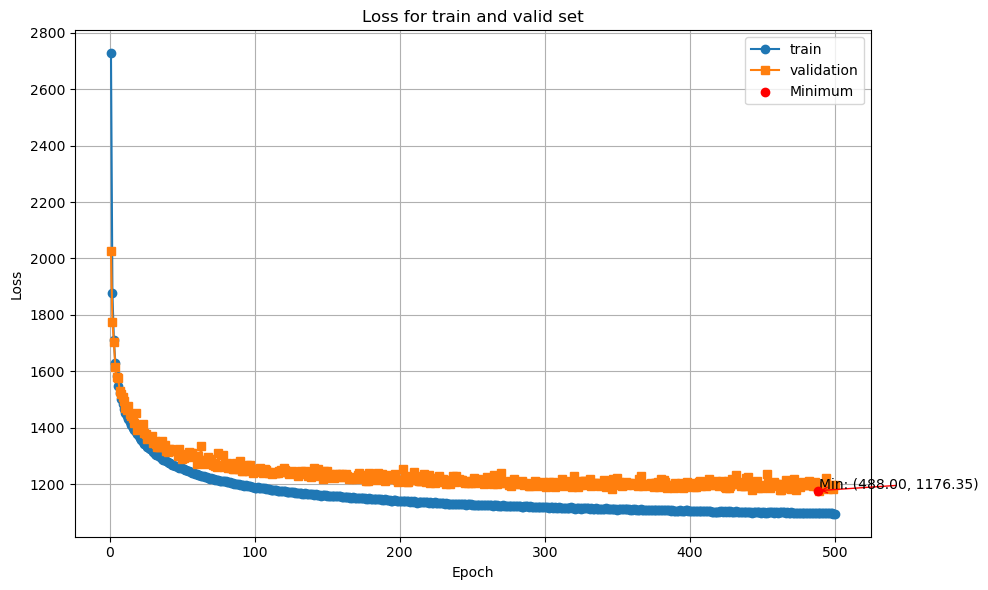

In [56]:
#compare the train process between shallow and deep network

min_idx = np.argmin(valid_losses)
y_min = valid_losses[min_idx]
plt.figure(figsize=(10, 6))
plt.plot(list(range(1, epochs+1)), train_losses, label='train', marker='o')
plt.plot(list(range(1, epochs+1)), valid_losses, label='validation', marker='s')
plt.scatter(min_idx, y_min, color='red', label='Minimum', zorder=5)
plt.annotate(f'Min: ({min_idx:.2f}, {y_min:.2f})',
             xy=(min_idx, y_min),
             xytext=(min_idx+1, y_min+5),
             arrowprops=dict(arrowstyle='->', color='red'),
             fontsize=10)
# plt.xticks(range(1, epochs+1)) 

plt.title('Loss for train and valid set')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.ylim(0,100)

plt.show()

In [57]:
# 5. Model Evaluation
deep_model.eval()
test_loss = 0
all_preds = []
all_targets = []
joints = []

with torch.no_grad():
    for data, target in test_loader:
        output = deep_model(data)
        test_loss += criterion(output, target).item()
       
        all_preds.extend(output)
        all_targets.extend(target)
        joints.extend(data)

test_loss /= len(test_loader)

print(f'Test Loss: {test_loss:.4f}')


Test Loss: 1166.1206


In [148]:
all_preds

[tensor([  0.2771, -40.1485, -10.6154,   2.8614,  -0.2303,   0.2386,   0.1352]),
 tensor([  0.2771, -40.1485, -10.6154,   2.8614,  -0.2303,   0.2386,   0.1352]),
 tensor([-1.5027e+02,  6.9119e+02,  3.0465e+00, -3.5352e+02,  1.5845e-01,
         -2.4003e+02, -1.9156e-01]),
 tensor([  0.2771, -40.1485, -10.6154,   2.8614,  -0.2303,   0.2386,   0.1352]),
 tensor([  0.2771, -40.1485, -10.6154,   2.8614,  -0.2303,   0.2386,   0.1352]),
 tensor([  0.2771, -40.1485, -10.6154,   2.8614,  -0.2303,   0.2386,   0.1352]),
 tensor([ 9.8796e-02,  2.3244e+02,  1.1092e-01,  2.1445e+01,  2.4408e-02,
         -9.8842e+01, -3.5976e-02]),
 tensor([ 27.0392, 290.7432,  13.9325,   1.6445,  59.9563,   3.2331, -25.8833]),
 tensor([  0.2771, -40.1485, -10.6154,   2.8614,  -0.2303,   0.2386,   0.1352]),
 tensor([ 6.3514e-01,  2.7272e+02,  2.1401e-01,  1.7505e+01, -2.1390e-02,
         -1.1710e+02,  1.2214e-01]),
 tensor([117.8320, 345.4314,  10.1049, 151.3487,   7.3267,  10.0028, -16.9827]),
 tensor([  0.2771, 

In [29]:
all_preds[0]

tensor([ 1.8099e-01, -4.0567e+01, -4.2083e+00,  2.6293e+00,  2.6354e-02,
         1.8763e-01, -9.1917e-02])

In [58]:
all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
error = all_preds - all_targets
abs_error = np.abs(error)
mean_error = np.mean(abs_error, axis=0)

In [59]:
abs_error

array([[7.14181423e-01, 1.38395805e+01, 2.40761638e+00, ...,
        4.19466347e-02, 2.50069737e-01, 4.65519428e-01],
       [4.77837896e+00, 9.73548603e+00, 2.94453669e+00, ...,
        7.55790710e+00, 2.27557731e+00, 5.98661900e-01],
       [1.08361778e+01, 2.46901596e+02, 1.31805506e+01, ...,
        8.43069553e-02, 1.74622250e+00, 6.73737717e+00],
       ...,
       [2.55300293e+01, 2.72099762e+01, 7.33568573e+00, ...,
        4.61104542e-01, 1.18770685e+01, 3.41648436e+00],
       [5.77667236e-01, 1.66072968e+02, 2.49908447e+01, ...,
        4.36992149e+01, 4.26591034e+01, 9.60536766e+00],
       [1.86176834e+01, 6.41611633e+01, 1.79284763e+00, ...,
        1.63547516e+01, 7.11866140e-01, 1.10590897e+01]], dtype=float32)

In [60]:
mean_error

array([12.157864 , 22.24234  ,  9.461305 , 11.695426 ,  5.5125813,
        5.2370415,  3.2067373], dtype=float32)

In [61]:
from sklearn.metrics import r2_score
r2_score(all_targets, all_preds, multioutput='uniform_average')  

0.7467411756515503

In [62]:
r2_score(all_targets, all_preds, multioutput='raw_values')       

array([0.7132975 , 0.9334818 , 0.9180648 , 0.89891076, 0.5819789 ,
       0.50260186, 0.6788522 ], dtype=float32)

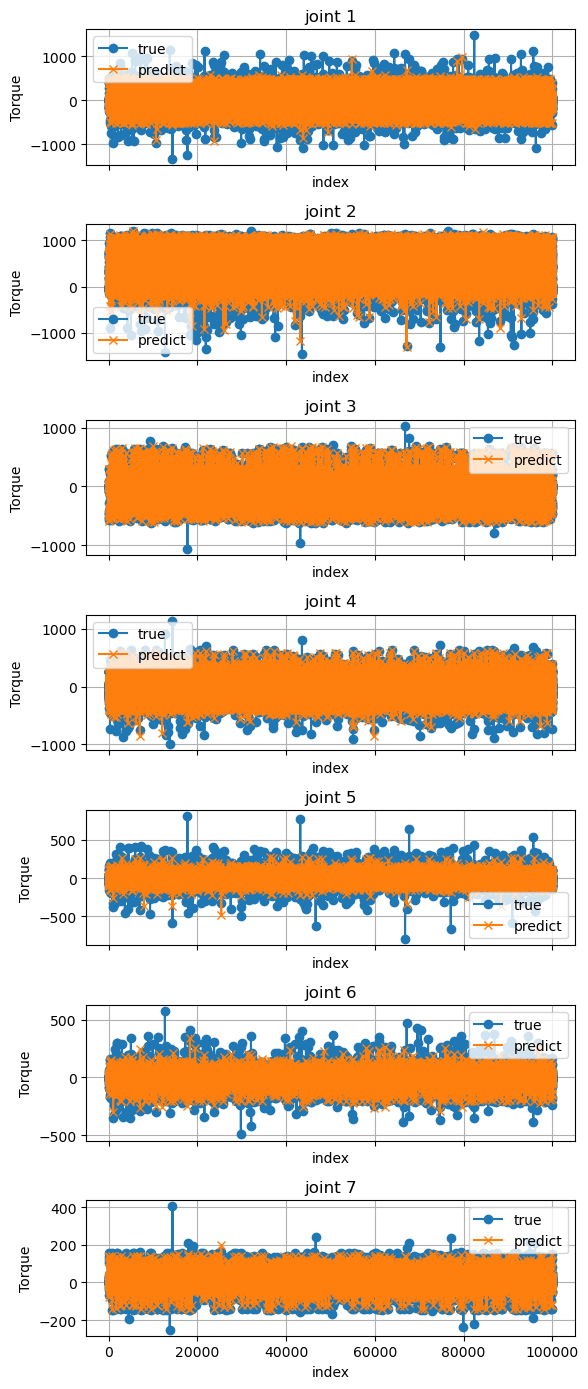

In [63]:
#show torqur values
fig, axes = plt.subplots(nrows=7, ncols=1, figsize=(6, 14), sharex=True)
for i, ax in enumerate(axes.flat):
    ax.plot(all_targets[:,i] , label='true', marker='o')
    ax.plot(all_preds[:,i] , label='predict', marker='x')
  
    ax.set_title(f'joint {i+1}')
    ax.set_xlabel('index')
    ax.set_ylabel('Torque')
    ax.legend()
    ax.grid()
    #ax.set_ylim(-200,200)

plt.tight_layout()
plt.savefig("torque_comparison_all.png", dpi=300)
plt.show()